# 01 — Diagnóstico e análise exploratória dos microdados do Censo da Educação Superior (2020–2023)

## Objetivo

Este notebook realiza o diagnóstico inicial dos arquivos da tabela **Microdados de Cadastro de Cursos** do Censo da Educação Superior, edições de 2020 a 2023.

A análise considera todas as colunas disponíveis nos arquivos originais. O objetivo é conhecer a estrutura, avaliar a qualidade e identificar diferenças entre as edições antes de selecionar variáveis ou realizar tratamentos.

### Escopo

- Inspeção dos arquivos Parquet e de seus metadados;
- dimensões, nomes e tipos das colunas;
- consumo de memória;
- valores ausentes;
- cardinalidade e frequências;
- estatísticas descritivas;
- comparação estrutural entre os anos.

**Importante:** os quatro conjuntos serão processados individualmente. Não será realizada concatenação nesta etapa.

## 1. Preparação do ambiente

As bibliotecas utilizadas são Pandas, NumPy, Matplotlib, PyArrow e ferramentas da biblioteca padrão do Python.

Caso alguma dependência não esteja instalada, execute a célula abaixo no ambiente do projeto.

In [ ]:
from pathlib import Path
import gc
import json
import os
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

## 2. Configuração dos caminhos

In [ ]:
PASTA_DADOS = Path("data/raw")

ARQUIVOS = {
    2020: PASTA_DADOS / "censo_superior_2020.parquet",
    2021: PASTA_DADOS / "censo_superior_2021.parquet",
    2022: PASTA_DADOS / "censo_superior_2022.parquet",
    2023: PASTA_DADOS / "censo_superior_2023.parquet",
}

PASTA_RESULTADOS = Path("../resultados/diagnostico")
PASTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

# Quantidade máxima de categorias exibidas nas tabelas de frequência.
TOP_CATEGORIAS = 20

# Limite para considerar uma variável de baixa cardinalidade.
# Acima desse limite, serão exibidas apenas as categorias mais frequentes.
LIMITE_BAIXA_CARDINALIDADE = 30

# Evita gerar gráficos para centenas de variáveis de uma só vez.
LIMITE_GRAFICOS_NULOS = 40

## 3. Verificação dos arquivos e inspeção dos metadados

Antes de carregar os dados, verificamos a existência dos arquivos e consultamos os metadados Parquet.

Essa etapa permite obter informações como quantidade de linhas, colunas, grupos de linhas, tamanho em disco e esquema físico, sem carregar integralmente os dados em um DataFrame.

In [ ]:
arquivos_validos = {}

for ano, caminho in ARQUIVOS.items():
    existe = caminho.exists()

    print(f"{ano}: {'Encontrado' if existe else 'NÃO ENCONTRADO'} — {caminho}")

    if existe:
        arquivos_validos[ano] = caminho

if not arquivos_validos:
    raise FileNotFoundError(
        "Nenhum arquivo foi encontrado. Verifique PASTA_DADOS e os nomes dos arquivos."
    )

2020: Encontrado — data/raw/censo_superior_2020.parquet
2021: Encontrado — data/raw/censo_superior_2021.parquet
2022: Encontrado — data/raw/censo_superior_2022.parquet
2023: Encontrado — data/raw/censo_superior_2023.parquet


In [ ]:
metadados = []

for ano, caminho in arquivos_validos.items():
    parquet_file = pq.ParquetFile(caminho)
    metadata = parquet_file.metadata

    metadados.append({
        "ano": ano,
        "arquivo": caminho.name,
        "tamanho_mb": caminho.stat().st_size / (1024 ** 2),
        "linhas": metadata.num_rows,
        "colunas": metadata.num_columns,
        "grupos_linhas": metadata.num_row_groups,
    })

    print(f"\n{'=' * 70}")
    print(f"ANO: {ano}")
    print(f"{'=' * 70}")
    print("Esquema:")
    print(parquet_file.schema)

df_metadados = pd.DataFrame(metadados).sort_values("ano")
display(df_metadados)

df_metadados.to_csv(
    PASTA_RESULTADOS / "01_metadados_arquivos.csv",
    index=False,
    encoding="utf-8-sig"
)


ANO: 2020
Esquema:
required group field_id=-1 schema {
  optional int64 field_id=-1 NU_ANO_CENSO;
  optional binary field_id=-1 NO_REGIAO (String);
  optional binary field_id=-1 CO_REGIAO (String);
  optional binary field_id=-1 NO_UF (String);
  optional binary field_id=-1 SG_UF (String);
  optional binary field_id=-1 CO_UF (String);
  optional binary field_id=-1 NO_MUNICIPIO (String);
  optional binary field_id=-1 CO_MUNICIPIO (String);
  optional binary field_id=-1 IN_CAPITAL (String);
  optional binary field_id=-1 TP_DIMENSAO (String);
  optional binary field_id=-1 TP_ORGANIZACAO_ACADEMICA (String);
  optional binary field_id=-1 TP_CATEGORIA_ADMINISTRATIVA (String);
  optional binary field_id=-1 TP_REDE (String);
  optional binary field_id=-1 CO_IES (String);
  optional binary field_id=-1 NO_CURSO (String);
  optional int64 field_id=-1 CO_CURSO;
  optional binary field_id=-1 NO_CINE_ROTULO (String);
  optional binary field_id=-1 CO_CINE_ROTULO2 (String);
  optional binary field_id=

,ano,arquivo,tamanho_mb,linhas,colunas,grupos_linhas
0,2020,censo_superior_2020.parquet,25.324720,344691,200,1
1,2021,censo_superior_2021.parquet,31.149302,444786,200,1
2,2022,censo_superior_2022.parquet,38.864389,573019,200,1
3,2023,censo_superior_2023.parquet,44.320319,671610,202,1


## 4. Funções auxiliares para o diagnóstico

As funções abaixo organizam os resultados de cada edição.

A análise de valores ausentes considera os nulos reconhecidos pelo Pandas. Códigos especiais, como `0`, `-1` ou outros valores definidos pelo Inep, não serão automaticamente tratados como ausentes. Essa interpretação depende dos dicionários de variáveis de cada edição.

In [ ]:
def resumo_memoria(df):
    memoria_bytes = df.memory_usage(index=True, deep=True).sum()
    return {
        "memoria_mb": memoria_bytes / (1024 ** 2),
        "memoria_gb": memoria_bytes / (1024 ** 3),
    }


def diagnostico_colunas(df, ano):
    return pd.DataFrame({
        "ano": ano,
        "coluna": df.columns,
        "tipo": [str(tipo) for tipo in df.dtypes],
        "nao_nulos": df.notna().sum().values,
        "nulos": df.isna().sum().values,
        "percentual_nulos": (df.isna().mean() * 100).values,
        "valores_distintos": df.nunique(dropna=True).values,
    })


def resumo_nulos(df):
    resultado = pd.DataFrame({
        "quantidade_nulos": df.isna().sum(),
        "percentual_nulos": df.isna().mean() * 100,
        "total_registros": len(df),
    })

    return resultado.sort_values(
        "percentual_nulos",
        ascending=False
    )


def resumo_cardinalidade(df):
    resultado = pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "valores_distintos": df.nunique(dropna=True),
        "valores_nulos": df.isna().sum(),
    })

    return resultado.sort_values(
        "valores_distintos",
        ascending=False
    )


def estatisticas_numericas(df):
    colunas_numericas = df.select_dtypes(include="number").columns

    if len(colunas_numericas) == 0:
        return pd.DataFrame()

    return df[colunas_numericas].describe(
        percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
    ).T


def estatisticas_categoricas(df):
    colunas = df.select_dtypes(
        include=["object", "string", "category", "bool"]
    ).columns

    if len(colunas) == 0:
        return pd.DataFrame()

    return df[colunas].describe().T

## 5. Diagnóstico individual dos arquivos

Nesta seção, cada arquivo é carregado e analisado separadamente.

Para cada edição serão apresentados:

1. dimensões e tipos;
2. memória ocupada;
3. valores ausentes;
4. cardinalidade;
5. estatísticas numéricas;
6. estatísticas categóricas.

O DataFrame de cada ano é descartado ao final do processamento para liberar memória.

In [ ]:
resultados_por_ano = {}

for ano, caminho in arquivos_validos.items():

    print("\n" + "=" * 90)
    print(f"DIAGNÓSTICO DO ANO {ano}")
    print("=" * 90)

    df = pd.read_parquet(caminho, engine="pyarrow")

    # 5.1 Informações gerais
    print("\nDimensões:", df.shape)
    print("\nTipos de dados:")
    display(df.dtypes.rename("tipo").to_frame())

    memoria = resumo_memoria(df)
    print(f"Memória ocupada pelo DataFrame: {memoria['memoria_mb']:.2f} MB "
          f"({memoria['memoria_gb']:.3f} GB)")

    print("\nInformações gerais:")
    df.info(memory_usage="deep")

    # 5.2 Diagnóstico por coluna
    colunas = diagnostico_colunas(df, ano)
    nulos = resumo_nulos(df)
    cardinalidade = resumo_cardinalidade(df)

    print("\nColunas com maior percentual de valores ausentes:")
    display(nulos.head(20))

    print("\nVariáveis com maior cardinalidade:")
    display(cardinalidade.head(20))

    # 5.3 Estatísticas numéricas
    numericas = estatisticas_numericas(df)

    print("\nEstatísticas das variáveis numéricas:")
    display(numericas)

    # 5.4 Estatísticas categóricas
    categoricas = estatisticas_categoricas(df)

    print("\nEstatísticas das variáveis categóricas:")
    display(categoricas)

    # 5.5 Exportação dos relatórios da edição
    prefixo = PASTA_RESULTADOS / f"{ano}"

    colunas.to_csv(
        f"{prefixo}_diagnostico_colunas.csv",
        index=False,
        encoding="utf-8-sig"
    )

    nulos.to_csv(
        f"{prefixo}_valores_nulos.csv",
        encoding="utf-8-sig"
    )

    cardinalidade.to_csv(
        f"{prefixo}_cardinalidade.csv",
        encoding="utf-8-sig"
    )

    numericas.to_csv(
        f"{prefixo}_estatisticas_numericas.csv",
        encoding="utf-8-sig"
    )

    categoricas.to_csv(
        f"{prefixo}_estatisticas_categoricas.csv",
        encoding="utf-8-sig"
    )

    resultados_por_ano[ano] = {
        "dimensoes": df.shape,
        "memoria_mb": memoria["memoria_mb"],
        "colunas": colunas,
    }

    del df, colunas, nulos, cardinalidade, numericas, categoricas
    gc.collect()

print("\nDiagnóstico individual concluído.")


DIAGNÓSTICO DO ANO 2020

Dimensões: (344691, 200)

Tipos de dados:


,tipo
NU_ANO_CENSO,Int64
NO_REGIAO,string[python]
CO_REGIAO,string[python]
NO_UF,string[python]
SG_UF,string[python]
...,...
QT_CONC_ATIV_EXTRACURRICULAR,string[python]
QT_MOB_ACADEMICA,string[python]
QT_ING_MOB_ACADEMICA,string[python]
QT_MAT_MOB_ACADEMICA,string[python]


Memória ocupada pelo DataFrame: 3287.97 MB (3.211 GB)

Informações gerais:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344691 entries, 0 to 344690
Columns: 200 entries, NU_ANO_CENSO to QT_CONC_MOB_ACADEMICA
dtypes: Int64(6), string(194)
memory usage: 3.2 GB

Colunas com maior percentual de valores ausentes:


,quantidade_nulos,percentual_nulos,total_registros
NO_REGIAO,6342,1.839909,344691
CO_REGIAO,6342,1.839909,344691
NO_UF,6342,1.839909,344691
SG_UF,6342,1.839909,344691
NO_MUNICIPIO,6342,1.839909,344691
CO_UF,6342,1.839909,344691
CO_MUNICIPIO,6342,1.839909,344691
IN_CAPITAL,6342,1.839909,344691
TP_GRAU_ACADEMICO,283,0.082103,344691
NU_ANO_CENSO,0,0.000000,344691



Variáveis com maior cardinalidade:


,tipo,valores_distintos,valores_nulos
CO_CURSO,Int64,42233,0
QT_INSCRITO_TOTAL,string,2957,0
QT_INSC_VG_NOVA,string,2804,0
CO_MUNICIPIO,string,2795,6342
NO_MUNICIPIO,string,2712,6342
CO_IES,string,2457,0
QT_VG_TOTAL,Int64,2292,0
QT_INSCRITO_TOTAL_DIURNO,string,1960,0
QT_VG_TOTAL_EAD,string,1884,0
QT_INSCRITO_TOTAL_NOTURNO,string,1630,0


... (31 outputs left out)

,count,mean,std,min,1%,25%,50%,75%,99%,max
NU_ANO_CENSO,671610.0,2023.0,0.0,2023.0,2023.0,2023.0,2023.0,2023.0,2023.0,2023.0
CO_CURSO,671610.0,1303104.367235,694730.76551,1.0,49369.09,1292569.0,1445199.0,1551486.0,1643597.3,50017101.0
QT_VG_TOTAL,671610.0,36.661105,822.32945,0.0,0.0,0.0,0.0,0.0,500.0,129782.0
QT_ING,671610.0,7.436149,31.837481,0.0,0.0,0.0,1.0,4.0,112.0,5765.0
QT_MAT,671610.0,14.855671,72.003004,0.0,0.0,1.0,2.0,5.0,271.0,11586.0
QT_CONC,671610.0,2.047005,12.111681,0.0,0.0,0.0,0.0,0.0,41.0,1478.0



Estatísticas das variáveis categóricas:


,count,unique,top,freq
NO_REGIAO,660571,5,Sudeste,270858
CO_REGIAO,660571,5,3,270858
NO_UF,660571,27,São Paulo,141697
SG_UF,660571,27,SP,141697
CO_UF,660571,27,35,141697
...,...,...,...,...
QT_CONC_ATIV_EXTRACURRICULAR,671610,251,0,643312
QT_MOB_ACADEMICA,671610,61,0,670015
QT_ING_MOB_ACADEMICA,671610,22,0,671541
QT_MAT_MOB_ACADEMICA,671610,64,0,670071



Diagnóstico individual concluído.


## 6. Frequência das variáveis categóricas

Esta seção investiga os valores mais frequentes das variáveis categóricas e das variáveis numéricas com baixa cardinalidade.

A distinção é importante porque algumas colunas armazenam códigos numéricos que representam categorias, e não quantidades.

Para evitar tabelas excessivamente grandes, são exibidos até `TOP_CATEGORIAS` valores por variável. Variáveis de alta cardinalidade não terão todas as categorias listadas.

In [ ]:
for ano, caminho in arquivos_validos.items():

    print("\n" + "=" * 90)
    print(f"FREQUÊNCIAS — {ano}")
    print("=" * 90)

    df = pd.read_parquet(caminho, engine="pyarrow")

    colunas_baixa_card = [
        coluna for coluna in df.columns
        if df[coluna].nunique(dropna=True) <= LIMITE_BAIXA_CARDINALIDADE
    ]

    for coluna in colunas_baixa_card:
        print(f"\n{coluna}")
        frequencias = (
            df[coluna]
            .value_counts(dropna=False)
            .head(TOP_CATEGORIAS)
            .rename_axis("valor")
            .reset_index(name="frequencia")
        )
        display(frequencias)

    del df
    gc.collect()


FREQUÊNCIAS — 2020

NU_ANO_CENSO


,valor,frequencia
0,2020,344691



NO_REGIAO


,valor,frequencia
0,Sudeste,137711
1,Sul,78302
2,Nordeste,63226
3,Centro-Oeste,31421
4,Norte,27689
5,<NA>,6342



CO_REGIAO


,valor,frequencia
0,3,137711
1,4,78302
2,2,63226
3,5,31421
4,1,27689
5,<NA>,6342


... (286 outputs left out)


QT_ING_MOB_ACADEMICA


,valor,frequencia
0,0,671541
1,1,36
2,2,8
3,16,3
4,14,2
5,25,2
6,28,2
7,20,2
8,3,1
9,27,1



QT_CONC_MOB_ACADEMICA


,valor,frequencia
0,0,671282
1,1,218
2,2,43
3,3,16
4,4,11
5,5,7
6,6,5
7,9,3
8,19,2
9,10,2


## 7. Visualização dos valores ausentes

Os gráficos permitem identificar rapidamente variáveis com maior concentração de valores ausentes.

Para preservar a legibilidade, o gráfico apresenta no máximo `LIMITE_GRAFICOS_NULOS` variáveis com maior percentual de ausência por edição.

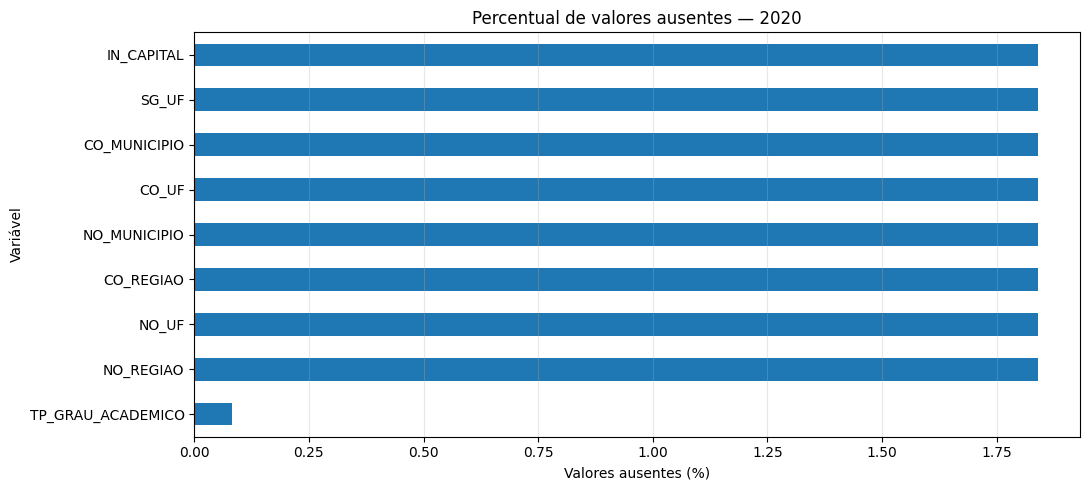

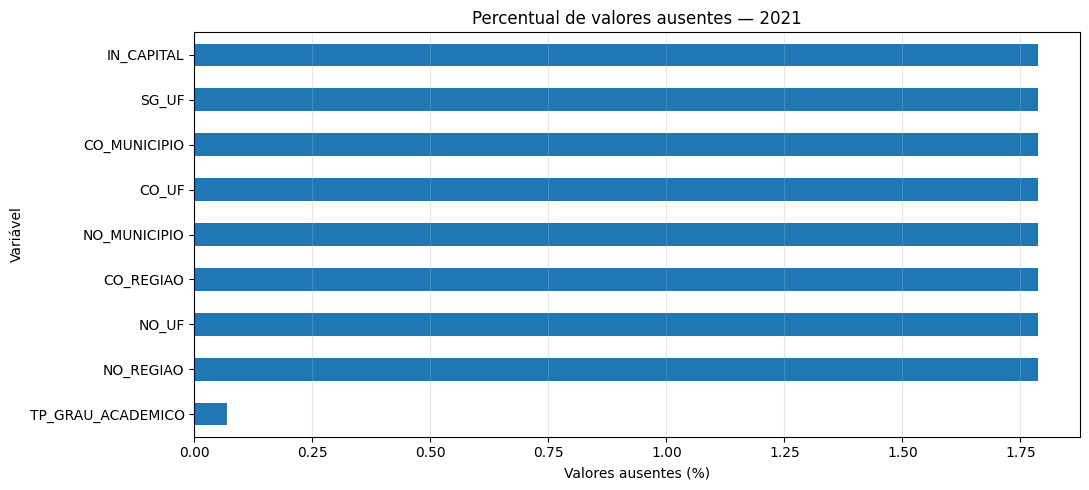

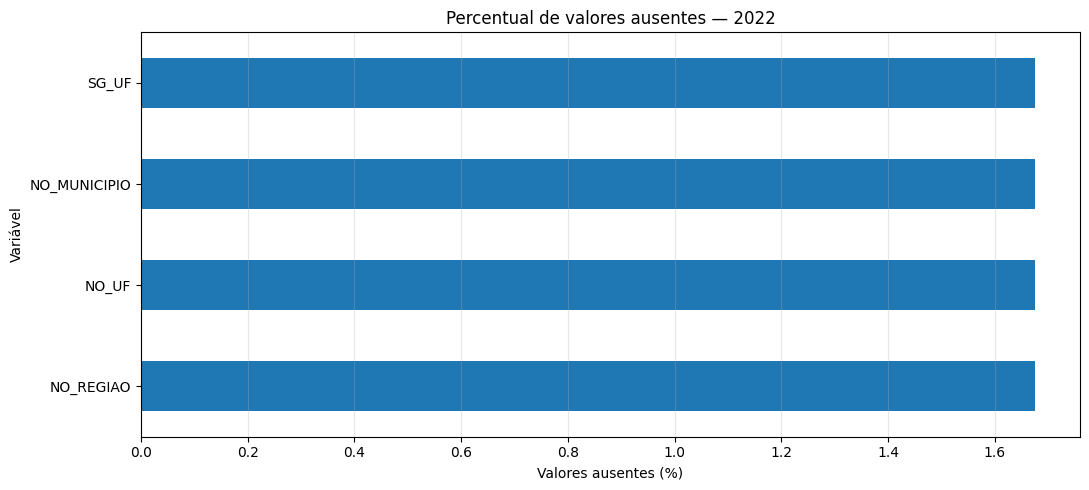

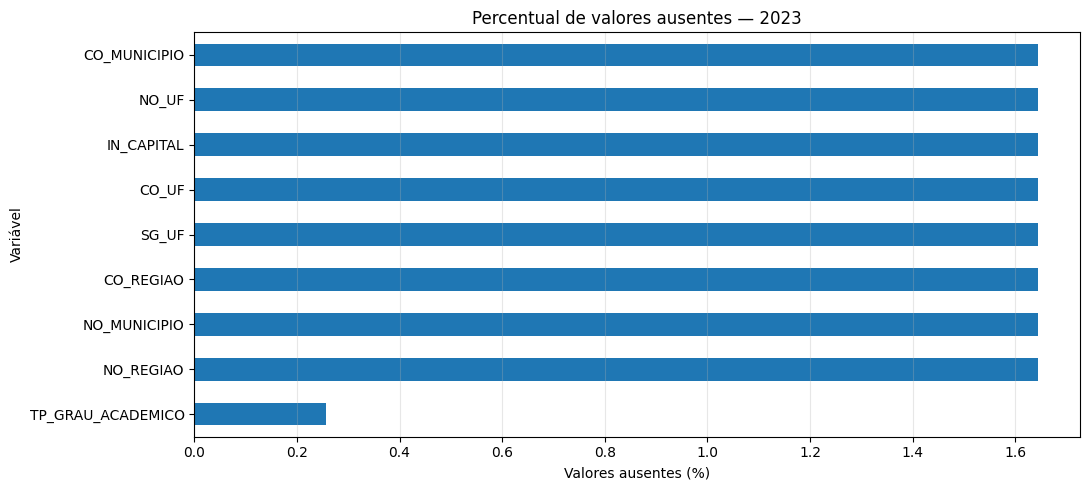

In [ ]:
for ano, caminho in arquivos_validos.items():

    df = pd.read_parquet(caminho, engine="pyarrow")

    nulos = resumo_nulos(df)
    nulos_plot = nulos[nulos["quantidade_nulos"] > 0].head(
        LIMITE_GRAFICOS_NULOS
    )

    if not nulos_plot.empty:
        ax = nulos_plot["percentual_nulos"].sort_values().plot(
            kind="barh",
            figsize=(11, max(5, len(nulos_plot) * 0.25)),
            title=f"Percentual de valores ausentes — {ano}"
        )

        ax.set_xlabel("Valores ausentes (%)")
        ax.set_ylabel("Variável")
        ax.grid(axis="x", alpha=0.3)
        plt.tight_layout()
        plt.show()
    else:
        print(f"{ano}: nenhuma variável apresenta valores nulos.")

    del df, nulos, nulos_plot
    gc.collect()

## 8. Comparação estrutural entre as edições

Agora comparamos os nomes e os tipos das colunas encontrados em cada ano.

Essa comparação permite identificar:

- colunas presentes em todas as edições;
- colunas ausentes em alguma edição;
- colunas que surgiram ou deixaram de existir;
- mudanças de tipo entre os anos.

Uma diferença de nome ou tipo não significa automaticamente incompatibilidade. Ela deverá ser confrontada com os dicionários de variáveis e os documentos metodológicos do Inep.

In [ ]:
# União dos nomes de todas as colunas identificadas.
todas_colunas = sorted({
    coluna
    for resultado in resultados_por_ano.values()
    for coluna in resultado["colunas"]["coluna"]
})

presenca_colunas = pd.DataFrame(index=todas_colunas)

for ano, resultado in resultados_por_ano.items():
    colunas_ano = resultado["colunas"].set_index("coluna")

    presenca_colunas[str(ano)] = [
        coluna in colunas_ano.index
        for coluna in todas_colunas
    ]

presenca_colunas.index.name = "coluna"

print("Presença das colunas por edição:")
display(presenca_colunas)

presenca_colunas.to_csv(
    PASTA_RESULTADOS / "comparacao_presenca_colunas.csv",
    encoding="utf-8-sig"
)

Presença das colunas por edição:


,2020,2021,2022,2023
coluna,,,,
CO_CINE_AREA_DETALHADA,True,True,True,True
CO_CINE_AREA_ESPECIFICA,True,True,True,True
CO_CINE_AREA_GERAL,True,True,True,True
CO_CINE_ROTULO,False,True,True,True
CO_CINE_ROTULO2,True,False,False,False
...,...,...,...,...
TP_GRAU_ACADEMICO,True,True,True,True
TP_MODALIDADE_ENSINO,True,True,True,True
TP_NIVEL_ACADEMICO,True,True,True,True


In [ ]:
# Comparação dos tipos de dados por coluna e ano.
tipos_por_ano = pd.DataFrame(index=todas_colunas)

for ano, resultado in resultados_por_ano.items():
    tipos = resultado["colunas"].set_index("coluna")["tipo"]
    tipos_por_ano[str(ano)] = tipos

tipos_por_ano.index.name = "coluna"

print("Tipos de dados por edição:")
display(tipos_por_ano)

tipos_por_ano.to_csv(
    PASTA_RESULTADOS / "comparacao_tipos_colunas.csv",
    encoding="utf-8-sig"
)

Tipos de dados por edição:


,2020,2021,2022,2023
coluna,,,,
CO_CINE_AREA_DETALHADA,string,string,string,string
CO_CINE_AREA_ESPECIFICA,string,string,string,string
CO_CINE_AREA_GERAL,string,string,string,string
CO_CINE_ROTULO,NaN,string,string,string
CO_CINE_ROTULO2,string,NaN,NaN,NaN
...,...,...,...,...
TP_GRAU_ACADEMICO,string,string,string,string
TP_MODALIDADE_ENSINO,string,string,string,string
TP_NIVEL_ACADEMICO,string,string,string,string


## 9. Resumo comparativo dos arquivos

Consolidamos informações gerais de cada edição sem concatenar os registros dos microdados.

In [ ]:
resumo_geral = []

for ano, resultado in resultados_por_ano.items():
    resumo_geral.append({
        "ano": ano,
        "registros": resultado["dimensoes"][0],
        "quantidade_colunas": resultado["dimensoes"][1],
        "memoria_dataframe_mb": resultado["memoria_mb"],
    })

df_resumo_geral = pd.DataFrame(resumo_geral).sort_values("ano")

display(df_resumo_geral)

df_resumo_geral.to_csv(
    PASTA_RESULTADOS / "resumo_geral_por_ano.csv",
    index=False,
    encoding="utf-8-sig"
)

,ano,registros,quantidade_colunas,memoria_dataframe_mb
0,2020,344691,200,3287.967791
1,2021,444786,200,4242.274571
2,2022,573019,200,5464.718308
3,2023,671610,202,6469.876741
